
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/11_Lab_LagevineII_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

In [2]:
N = 8
Zr = stats.norm(loc=0, scale=1)
Z = Zr.rvs(size=N*N)

In [3]:
sigma=0.5
epsilon = sigma*Z
e = epsilon

In [4]:
np.std(epsilon)

np.float64(0.5037199230616184)

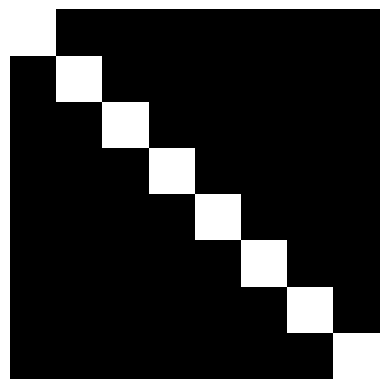

In [5]:
X = np.eye(N)
x = X.flatten()  # Vector con N² píxeles

plt.imshow(x.reshape(N, N), cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

ENTRADA: imágenes originales y niveles de ruido σ

Normalizar las imágenes
Separar datos de entrenamiento y evaluación
Inicializar los parámetros θ del modelo

REPETIR hasta completar el entrenamiento:
    Seleccionar un lote de imágenes originales x
    Seleccionar un nivel de ruido σ

    Generar ruido nuevo: e = σ · Normal(0, I)
    Construir imágenes perturbadas: y = x + e

    Calcular el campo objetivo: S_objetivo = −e / σ²
    Predecir el campo: S_predicho = sθ(y, σ)

    Pérdida = ½ · promedio(||S_predicho − S_objetivo||²)
    Actualizar θ usando el gradiente de la pérdida

Evaluar el modelo con los datos reservados
SALIDA: campo aprendido sθ(y, σ)

In [6]:
#x = np.array([0.2, 0.8, 0.4, 0.6])
#e

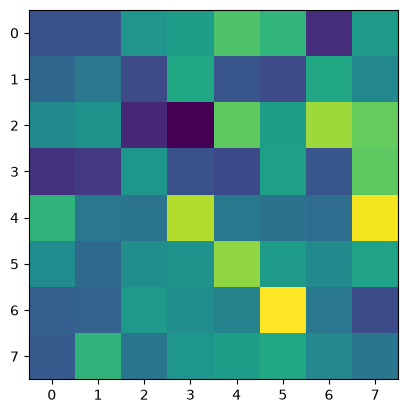

In [7]:
# Ruuido gaussian
Sobjetivo = -e/sigma**2
plt.imshow(Sobjetivo.reshape(N, N))

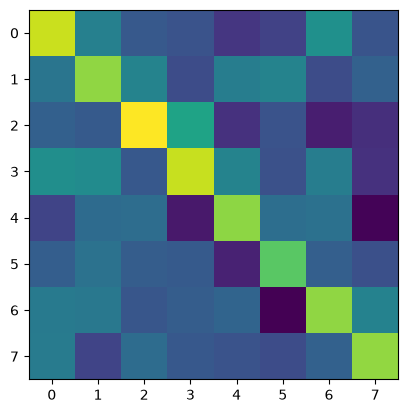

In [8]:
xp = x + e*sigma
plt.imshow(xp.reshape(8,8))

paso   500: pérdida =     0.000   A =   -99.993   media(B) = 12.499
paso  1000: pérdida =     0.000   A =  -100.000   media(B) = 12.500
paso  1500: pérdida =     0.000   A =  -100.000   media(B) = 12.500
paso  2000: pérdida =     0.000   A =  -100.000   media(B) = 12.500
paso  2500: pérdida =     0.000   A =  -100.000   media(B) = 12.500
paso  3000: pérdida =     0.000   A =  -100.000   media(B) = 12.500

A aprendido = -100.00    valor óptimo -1/σ² = -100.00
max |B - x/σ²| = 0.000    (óptimo: B = x/σ², escala 100)
Pérdida final = 1.15e-28  (con el score exacto la pérdida es 0: S_pred = -(y-x)/σ² = -e/σ²)


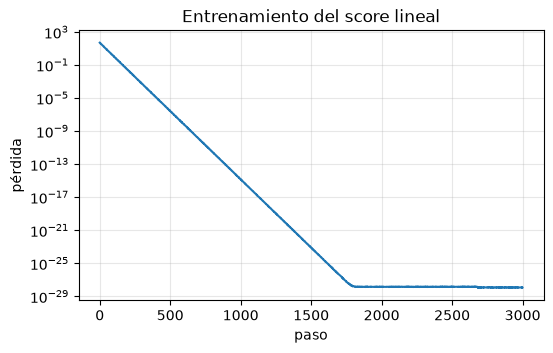

In [9]:
# Construir algoritmo: aprender un campo score lineal  s_θ(y) = A·y + B  (θ = {A escalar, B vector de N² píxeles})
# con denoising score matching, siguiendo el pseudocódigo anterior.
sigma = 0.1        # nivel de ruido (el paso dt = 0.001 de la generación está pensado para σ = 0.1, A ≈ -100)
rng_ent = np.random.default_rng(0)

def entrenar_score_lineal(x, sigma, n_pasos=3000, lote=64, lr=0.5, rng=rng_ent, verbose=True):
    """Minimiza  L = ½ <||A y + B - (-e/σ²)||²>  con y = x + e,  e ~ N(0, σ² I).
    El paso en A se divide por <y²> (la curvatura de L en la dirección de A) para que la misma tasa de
    aprendizaje funcione con cualquier σ; en B la curvatura ya es 1."""
    D_ = x.size
    A, B = 0.0, np.zeros(D_)
    hist = []
    for paso in range(n_pasos):
        e = rng.normal(0, sigma, size=(lote, D_))          # ruido nuevo en cada paso
        y = x + e
        S_obj = -e / sigma**2
        S_pred = A * y + B
        err = S_pred - S_obj
        hist.append(0.5 * np.mean(err**2))
        # gradientes de L respecto a A y B (promediando sobre el lote y los píxeles)
        gA = np.mean(err * y)
        gB = np.mean(err, axis=0)
        A -= lr * gA / np.mean(y**2)                       # paso normalizado por la curvatura en A
        B -= lr * gB
        if verbose and (paso + 1) % 500 == 0:
            print(f"paso {paso+1:5d}: pérdida = {hist[-1]:9.3f}   A = {A:9.3f}   media(B) = {B.mean():.3f}")
    return A, B, np.array(hist)

A, B, hist_lin = entrenar_score_lineal(x, sigma)

print(f"\nA aprendido = {A:.2f}    valor óptimo -1/σ² = {-1/sigma**2:.2f}")
print(f"max |B - x/σ²| = {np.abs(B - x / sigma**2).max():.3f}    (óptimo: B = x/σ², escala {1/sigma**2:.0f})")
print(f"Pérdida final = {hist_lin[-1]:.2e}  (con el score exacto la pérdida es 0: S_pred = -(y-x)/σ² = -e/σ²)")

plt.figure(figsize=(6, 3.5))
plt.semilogy(hist_lin)
plt.xlabel("paso"); plt.ylabel("pérdida"); plt.grid(alpha=.3); plt.title("Entrenamiento del score lineal")
plt.show()


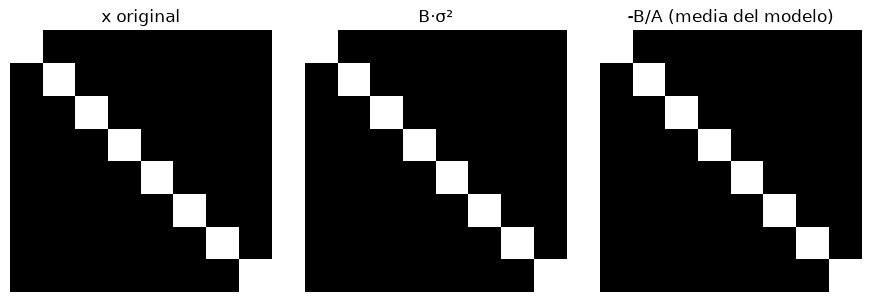

In [10]:
# ¿Por qué A → -1/σ² y B → x/σ²?
# Con un solo dato x, la densidad perturbada es p_σ(y) = N(y; x, σ² I) y su score exacto es
#   ∇_y log p_σ(y) = -(y - x)/σ² = (-1/σ²)·y + x/σ²,
# que es exactamente lineal. El modelo lineal puede representarlo sin error.
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a_, im_, t_ in zip(ax, [x, B * sigma**2, -B / A], ["x original", "B·σ²", "-B/A (media del modelo)"]):
    a_.imshow(im_.reshape(N, N), cmap="gray", vmin=0, vmax=1); a_.set_title(t_); a_.axis("off")
plt.tight_layout(); plt.show()


ENTRADA: imagen perturbada y, nivel de ruido σ,
         campo aprendido sθ

Calcular el campo: S = sθ(y, σ)

Estimar la imagen limpia:
    x_estimada = y + σ² · S

Si conocemos la imagen original:
    Comparar la estimación con ella
    Calcular el error de recuperación

SALIDA: imagen limpia estimada

In [11]:
rng_prueba = np.random.default_rng(123)

e_prueba = rng_prueba.normal(0, sigma, size=x.shape)
x_prueba = x + e_prueba

# 2. Evaluar el campo aprendido.
S_prueba = A * x_prueba + B

# 3. Recuperar la imagen usando ese campo.
x_recuperado = x_prueba + sigma**2 * S_prueba

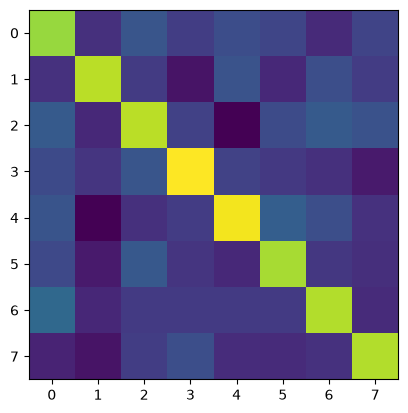

In [12]:
plt.imshow(x_prueba.reshape(8,8))

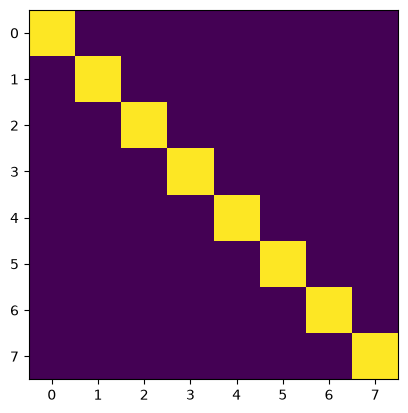

In [13]:
plt.imshow(x_recuperado.reshape(8,8))

**Recuperación con el score aprendido.** $\hat x = y + \sigma^2 s_\theta(y)$ es la fórmula de Tweedie: el valor esperado de la imagen limpia dada la imagen con ruido. Como el modelo aprendió $A \approx -1/\sigma^2$, se tiene $\hat x \approx y - (y - x) = x$, y la imagen se recupera casi exactamente. Con un solo dato de entrenamiento esto es trivial: el modelo memorizó $x$.


In [14]:
mse_ruido = np.mean((x_prueba - x)**2)
mse_rec = np.mean((x_recuperado - x)**2)
print(f"MSE con ruido = {mse_ruido:.5f}   MSE recuperada = {mse_rec:.2e}")


MSE con ruido = 0.00863   MSE recuperada = 1.93e-32


# Langevine

ENTRADA: campo aprendido, niveles σ de mayor a menor,
         número de pasos K y constante pequeña c

Inicializar desde ruido:
    Y = μ + σ_max · Normal(0, I)
    μ es la media de las imágenes de entrenamiento

PARA cada nivel σ, desde σ_max hasta σ_min:
    Elegir el paso: h = c · σ²

    REPETIR K veces:
        Calcular el campo: S = sθ(Y, σ)
        Generar ruido nuevo: Z = Normal(0, I)

        Actualizar mediante Langevin:
            Y = Y + h · S + √(2h) · Z

Opcionalmente aplicar la recuperación final:
    Y = Y + σ_min² · sθ(Y, σ_min)

SALIDA: imagen generada

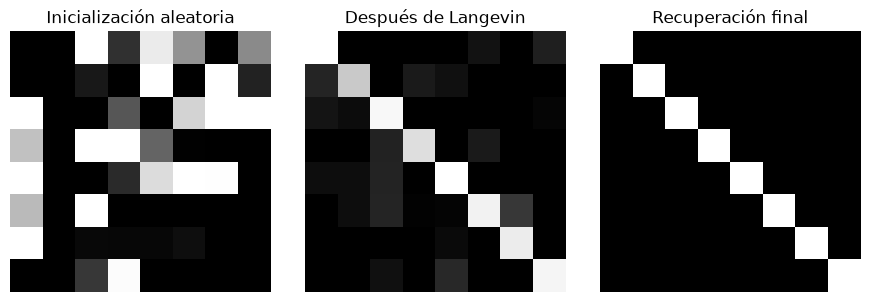

In [15]:
rng_generacion = np.random.default_rng(123)

# Inicialización independiente de la imagen original.
Y = rng_generacion.normal(0, 1, size=x.shape)
Y_inicial = Y.copy()

dt = 0.001  # Para sigma = 0.1 y A cercano a -100.
n_pasos = 1000

# Aquí entra Langevin.
for paso in range(n_pasos):

    S = A * Y + B
    Z = rng_generacion.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

# Recuperación final: es una operación distinta.
Y_recuperada = Y + sigma**2 * (A * Y + B)

fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparaciones = [
    (Y_inicial, "Inicialización aleatoria"),
    (Y, "Después de Langevin"),
    (Y_recuperada, "Recuperación final")
]

for eje, (imagen, titulo) in zip(ejes, comparaciones):
    eje.imshow(
        np.clip(imagen.reshape(N, N), 0, 1),
        cmap="gray", vmin=0, vmax=1
    )
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Langevin con varios niveles de σ (pseudocódigo "annealed Langevin")
# Entrenamos un score lineal para cada nivel de ruido, de mayor a menor.
sigmas = np.geomspace(1.0, 0.05, 8)
modelos_sigma = {}
for s_ in sigmas:
    A_s, B_s, _ = entrenar_score_lineal(x, s_, n_pasos=2000, verbose=False)
    modelos_sigma[s_] = (A_s, B_s)
    print(f"σ = {s_:.3f}:  A = {A_s:9.2f}  (óptimo {-1/s_**2:9.2f})")


σ = 1.000:  A =     -1.00  (óptimo     -1.00)
σ = 0.652:  A =     -2.35  (óptimo     -2.35)


σ = 0.425:  A =     -5.54  (óptimo     -5.54)
σ = 0.277:  A =    -13.04  (óptimo    -13.04)


σ = 0.181:  A =    -30.68  (óptimo    -30.68)
σ = 0.118:  A =    -72.21  (óptimo    -72.21)


σ = 0.077:  A =   -169.96  (óptimo   -169.96)
σ = 0.050:  A =   -399.98  (óptimo   -400.00)


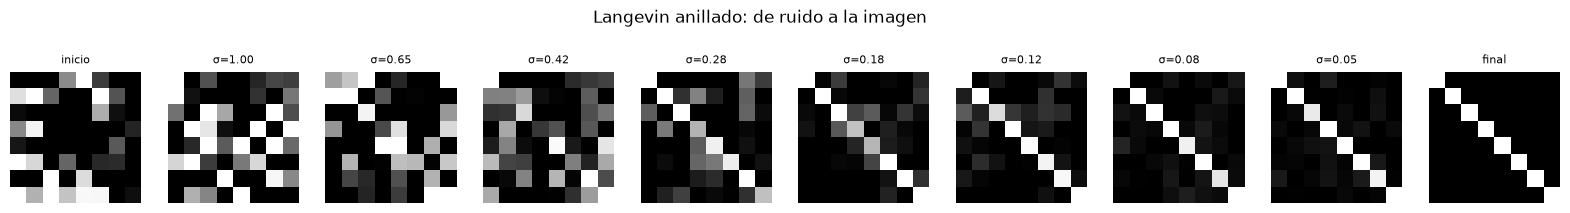

MSE de la muestra final respecto a x: 7.46e-12


In [17]:
def langevin_anillado(modelos, sigmas, K=100, c=0.05, rng=None, mu=0.0, guardar=False):
    """Y = μ + σ_max·N(0,I); para cada σ (de mayor a menor): K pasos  Y ← Y + h S + sqrt(2h) Z, con h = c σ²."""
    rng = rng or np.random.default_rng()
    Y = mu + sigmas[0] * rng.normal(size=N * N)
    tray = [Y.copy()]
    for s_ in sigmas:
        A_s, B_s = modelos[s_]
        h = c * s_**2
        for _ in range(K):
            Y = Y + h * (A_s * Y + B_s) + np.sqrt(2 * h) * rng.normal(size=Y.shape)
        tray.append(Y.copy())
    A_s, B_s = modelos[sigmas[-1]]
    Y_final = Y + sigmas[-1]**2 * (A_s * Y + B_s)          # recuperación final
    return Y, Y_final, tray

rng_g = np.random.default_rng(5)
Y_al, Y_al_final, tray = langevin_anillado(modelos_sigma, sigmas, rng=rng_g, mu=x.mean())

fig, ax = plt.subplots(1, len(tray) + 1, figsize=(2 * (len(tray) + 1), 2.3))
for i, (a_, im_) in enumerate(zip(ax, tray + [Y_al_final])):
    a_.imshow(np.clip(im_.reshape(N, N), 0, 1), cmap="gray", vmin=0, vmax=1); a_.axis("off")
    a_.set_title("inicio" if i == 0 else ("final" if i == len(tray) else f"σ={sigmas[i-1]:.2f}"), fontsize=8)
plt.suptitle("Langevin anillado: de ruido a la imagen", y=1.05); plt.show()
print(f"MSE de la muestra final respecto a x: {np.mean((Y_al_final - x)**2):.2e}")


In [18]:
# Comparación: Langevin con un solo σ (celda anterior) vs anillado
print(f"Un solo σ = {sigma}:  MSE(Y, x) = {np.mean((Y - x)**2):.4f}   MSE(recuperación final, x) = {np.mean((Y_recuperada - x)**2):.2e}")
print(f"Anillado:          MSE(Y, x) = {np.mean((Y_al - x)**2):.4f}   MSE(recuperación final, x) = {np.mean((Y_al_final - x)**2):.2e}")
print(f"Varianza esperada de las muestras de Langevin con σ_min: σ² = {sigmas[-1]**2:.4f};  con σ = {sigma}: {sigma**2:.4f}")


Un solo σ = 0.1:  MSE(Y, x) = 0.0099   MSE(recuperación final, x) = 2.24e-32
Anillado:          MSE(Y, x) = 0.0028   MSE(recuperación final, x) = 7.46e-12
Varianza esperada de las muestras de Langevin con σ_min: σ² = 0.0025;  con σ = 0.1: 0.0100


**Conclusión de la primera parte.** Con una sola imagen de entrenamiento, el score lineal aprendido coincide con el score exacto $-(y-x)/\sigma^2$, porque $A \to -1/\sigma^2$ y $B \to x/\sigma^2$. Por eso la dinámica de Langevin genera muestras de $\mathcal{N}(x, \sigma^2 I)$: la imagen original más ruido de amplitud $\sigma$. El paso de recuperación final quita ese ruido. La versión anillada (de $\sigma_{max}$ a $\sigma_{min}$) arranca de ruido puro con escala grande y va afinando: el resultado final tiene ruido $\sigma_{min} = 0.05$, menor que el de un solo nivel. El modelo es demasiado simple para generar algo distinto de $x$; las siguientes secciones lo extienden a muchas imágenes.


# Caso con más imagenes

In [ ]:
%pip -q install datasets

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

datos = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)
perros = []

for ejemplo in datos:
    if ejemplo["label"] == 5:  # Perro
        perros.append(np.array(ejemplo["img"].convert("RGB")))

        if len(perros) % 25 == 0:
            print(f"Cargados: {len(perros)} perros")

        if len(perros) == 1000:
            break


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

Cargados: 25 perros
Cargados: 50 perros
Cargados: 75 perros
Cargados: 100 perros
Cargados: 125 perros
Cargados: 150 perros
Cargados: 175 perros
Cargados: 200 perros
Cargados: 225 perros
Cargados: 250 perros
Cargados: 275 perros
Cargados: 300 perros
Cargados: 325 perros
Cargados: 350 perros
Cargados: 375 perros
Cargados: 400 perros
Cargados: 425 perros
Cargados: 450 perros
Cargados: 475 perros
Cargados: 500 perros
Cargados: 525 perros
Cargados: 550 perros
Cargados: 575 perros
Cargados: 600 perros
Cargados: 625 perros
Cargados: 650 perros
Cargados: 675 perros
Cargados: 700 perros
Cargados: 725 perros
Cargados: 750 perros
Cargados: 775 perros
Cargados: 800 perros
Cargados: 825 perros
Cargados: 850 perros
Cargados: 875 perros
Cargados: 900 perros
Cargados: 925 perros
Cargados: 950 perros
Cargados: 975 perros
Cargados: 1000 perros


Forma: (1000, 32, 32, 3)


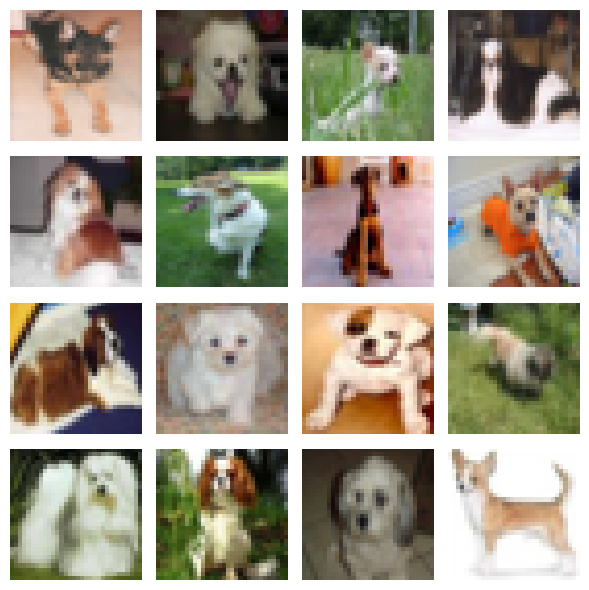

In [ ]:
X_perros = np.stack(perros)
print("Forma:", X_perros.shape)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, imagen in zip(axes.ravel(), X_perros[:16]):
    ax.imshow(imagen)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
X_entrenamiento = X_perros.astype(np.float32) / 127.5 - 1.0

In [ ]:
rng = np.random.default_rng(42)
sigma = 0.3

# Ruido independiente para cada imagen, píxel y canal
epsilon = rng.normal(
    loc=0,
    scale=sigma,
    size=X_entrenamiento.shape
).astype(np.float32)

X_ruidosas = X_entrenamiento + epsilon

# Campo objetivo para entrenar
S_objetivo = -epsilon / sigma**2

print("Imágenes limpias:", X_entrenamiento.shape)
print("Imágenes ruidosas:", X_ruidosas.shape)
print("Score objetivo:", S_objetivo.shape)

Imágenes limpias: (1000, 32, 32, 3)
Imágenes ruidosas: (1000, 32, 32, 3)
Score objetivo: (1000, 32, 32, 3)


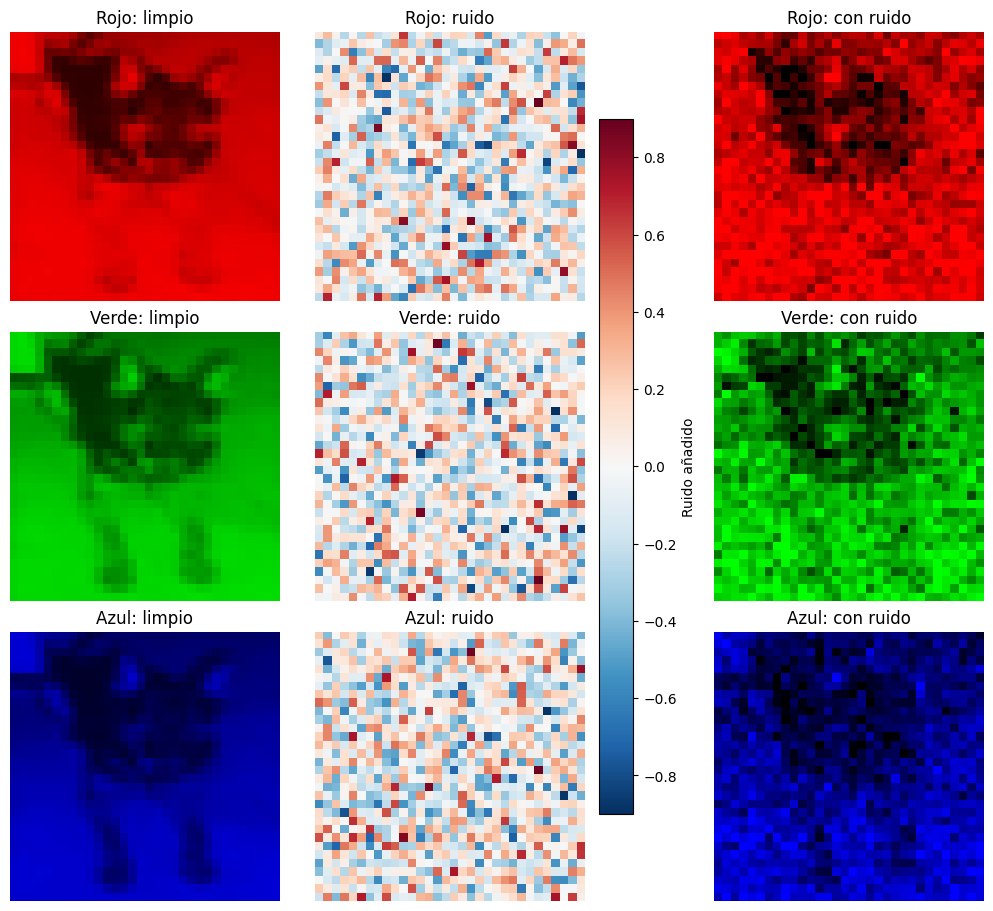

In [ ]:
i = 0
limpia = np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
ruidosa = np.clip((X_ruidosas[i] + 1) / 2, 0, 1)

nombres = ["Rojo", "Verde", "Azul"]

fig, axes = plt.subplots(
    3, 3, figsize=(10, 9), constrained_layout=True
)

for canal, nombre in enumerate(nombres):

    # Mostrar únicamente este canal en su color
    limpia_canal = np.zeros_like(limpia)
    limpia_canal[:, :, canal] = limpia[:, :, canal]

    ruidosa_canal = np.zeros_like(ruidosa)
    ruidosa_canal[:, :, canal] = ruidosa[:, :, canal]

    axes[canal, 0].imshow(limpia_canal)
    axes[canal, 0].set_title(f"{nombre}: limpio")

    im = axes[canal, 1].imshow(
        epsilon[i, :, :, canal],
        cmap="RdBu_r",
        vmin=-3 * sigma,
        vmax=3 * sigma
    )
    axes[canal, 1].set_title(f"{nombre}: ruido")

    axes[canal, 2].imshow(ruidosa_canal)
    axes[canal, 2].set_title(f"{nombre}: con ruido")

for ax in axes.ravel():
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[:, 1].tolist(),
    shrink=0.8,
    label="Ruido añadido"
)

plt.show()

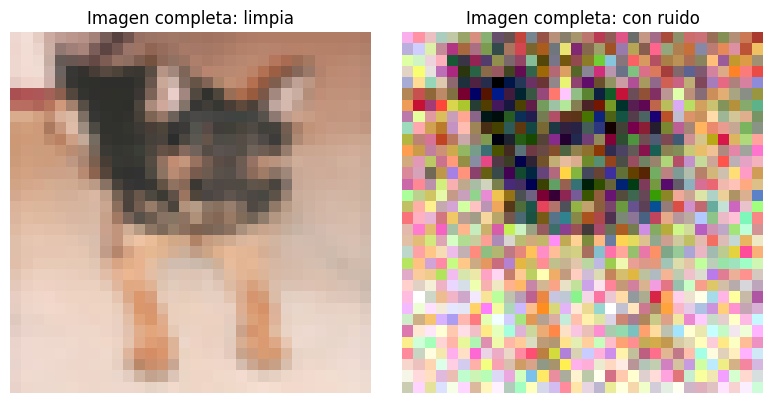

In [ ]:
i = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(
    np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
)
axes[0].set_title("Imagen completa: limpia")
axes[1].imshow(
    np.clip((X_ruidosas[i] + 1) / 2, 0, 1)
)
axes[1].set_title("Imagen completa: con ruido")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# X_entrenamiento ya debe estar normalizado a [-1, 1]
corte = int(0.8 * len(X_entrenamiento))
datos = X_entrenamiento[:corte]
evaluacion = X_entrenamiento[corte:]

# Parámetros iniciales
a = 0.0
B = np.zeros_like(datos[0])

D = B.size  # Número de componentes: píxeles × canales

lr_a = 0.01
lr_B = lr_a * D  # Compensa el promedio sobre D componentes

Paso 200: pérdida = 4.3932
Paso 400: pérdida = 4.0584
Paso 600: pérdida = 4.0082
Paso 800: pérdida = 4.1237
Paso 1000: pérdida = 3.9600
Paso 1200: pérdida = 4.0454
Paso 1400: pérdida = 4.1441
Paso 1600: pérdida = 4.0803
Paso 1800: pérdida = 4.2598
Paso 2000: pérdida = 3.9349
a aprendido: -3.0381432


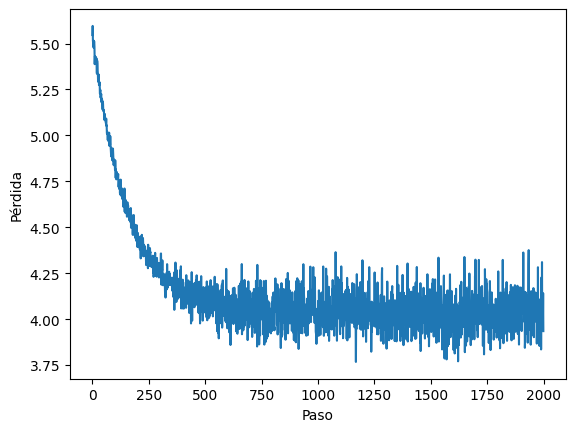

In [ ]:
n_pasos = 2000
historia = []
for paso in range(n_pasos):
    # Seleccionar un grupo de imágenes
    indices = rng.integers(0, len(datos), size=32)
    X = datos[indices]
    # Agregar ruido nuevo
    epsilon = rng.normal(0, sigma, size=X.shape).astype(np.float32)
    Y = X + epsilon
    # Score objetivo y score predicho
    S_objetivo = -epsilon / sigma**2

    S_predicho = a * Y + B



    error = S_predicho - S_objetivo
    loss = 0.5 * np.mean(error**2)
    # Gradientes de esa pérdida
    grad_a = np.mean(error * Y)
    grad_B = np.mean(error, axis=0) / D

    # Actualizar los parámetros
    a -= lr_a * grad_a
    B -= lr_B * grad_B

    historia.append(loss)

    if (paso + 1) % 200 == 0:
        print(f"Paso {paso + 1}: pérdida = {loss:.4f}")

print("a aprendido:", a)

plt.plot(historia)
plt.xlabel("Paso")
plt.ylabel("Pérdida")
plt.show()

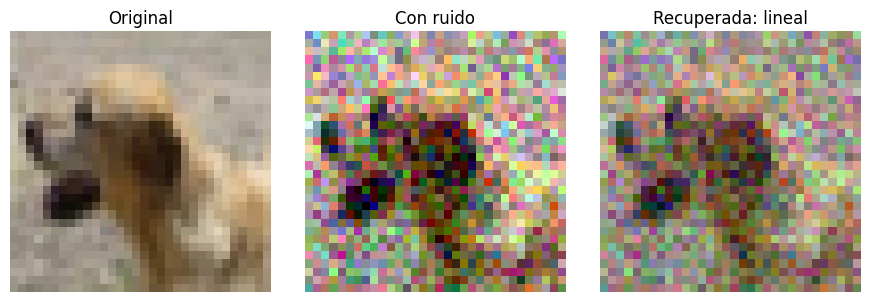

MSE con ruido: 0.0881564
MSE recuperada: 0.05862242


In [ ]:
X = evaluacion[4]

epsilon = rng.normal(
    0, sigma, size=X.shape
).astype(np.float32)

Y = X + epsilon

S_predicho = a * Y + B
X_recuperada = Y + sigma**2 * S_predicho

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

imagenes = [X, Y, X_recuperada]
titulos = ["Original", "Con ruido", "Recuperada: lineal"]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("MSE con ruido:", np.mean((Y - X)**2))
print("MSE recuperada:", np.mean((X_recuperada - X)**2))

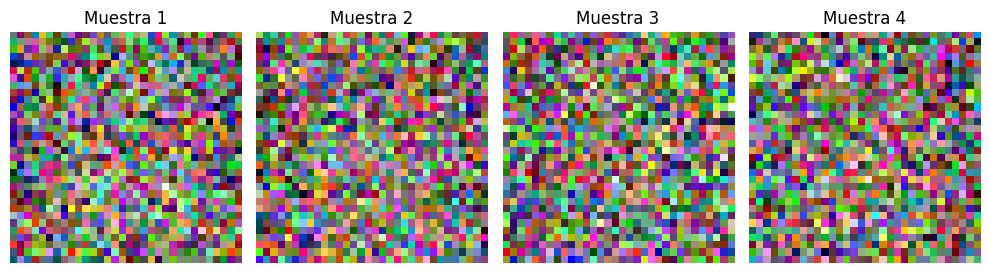

In [ ]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0 para tener una distribución estable.")

# Cuatro imágenes inicializadas con ruido puro
Y = rng.normal(size=(4,) + B.shape).astype(np.float32)

dt = 0.05 / abs(a)  # Paso pequeño respecto a la escala del campo

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(np.clip((Y[i] + 1) / 2, 0, 1))
    ax.set_title(f"Muestra {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0.")

n_muestras = 200

Y = rng.normal(
    size=(n_muestras,) + B.shape
).astype(np.float32)

dt = 0.05 / abs(a)

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape).astype(np.float32)

    Y = Y + dt * S + np.sqrt(2 * dt) * Z
# Promedio de las muestras, sin recortar sus valores
promedio = Y.mean(axis=0)
# Promedio esperado del modelo lineal
media_modelo = -B / a

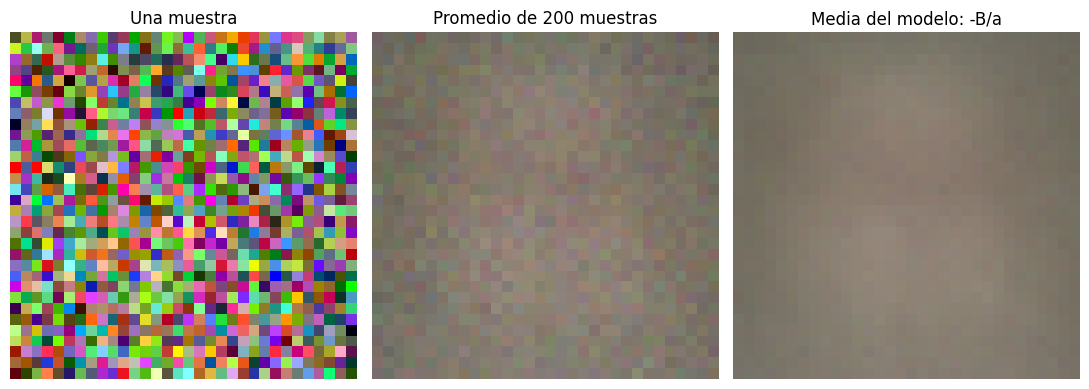

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

imagenes = [Y[0], promedio, media_modelo]
titulos = [
    "Una muestra",
    f"Promedio de {n_muestras} muestras",
    "Media del modelo: -B/a"
]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Lo que muestra el modelo lineal con 1000 perros.** Con muchas imágenes, $s_\theta(y) = a\,y + B$ solo puede representar una **gaussiana isotrópica** $\mathcal{N}(-B/a,\ -1/a\cdot I)$. Langevin genera la imagen media $-B/a$ (un "perro promedio" borroso) más ruido independiente en cada píxel. El promedio de 200 muestras coincide con $-B/a$, pero ninguna muestra individual parece un perro, porque el modelo lineal no captura correlaciones entre píxeles ni estructura espacial. Hace falta un modelo no lineal, como la red convolucional y la U-Net de las secciones siguientes.


In [ ]:
%pip install -q pillow numpy matplotlib

In [19]:
import json
from urllib.request import urlopen
from io import BytesIO
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

N = 100  # Puedes empezar con 20 para descargar todavía menos.
TAMANO = 64

carpeta = Path("flores_64")
carpeta.mkdir(exist_ok=True)

url = (
    "https://datasets-server.huggingface.co/rows?"
    "dataset=nkirschi/oxford-flowers&config=default&split=train"
    f"&offset=0&length={N}"
)

archivos = [carpeta / f"flor_{i:03d}.png" for i in range(N)]

# Solo se consulta internet si falta alguna imagen (las ya descargadas se reutilizan).
if not all(a.exists() for a in archivos):
    with urlopen(url, timeout=60) as respuesta:
        filas = json.load(respuesta)["rows"]
    for archivo, fila in zip(archivos, filas):
        if not archivo.exists():
            with urlopen(fila["row"]["image"]["src"], timeout=60) as respuesta:
                imagen = Image.open(BytesIO(respuesta.read())).convert("RGB")
            imagen = ImageOps.fit(imagen, (TAMANO, TAMANO))
            imagen.save(archivo)

imagenes = []
for archivo in archivos:

    with Image.open(archivo) as imagen:
        imagenes.append(np.array(imagen.convert("RGB")))

# Valores entre 0 y 1, listos para trabajar después con Keras.
imagenes = np.array(imagenes, dtype="float32") / 255.0
print("Forma:", imagenes.shape)


Forma: (100, 64, 64, 3)


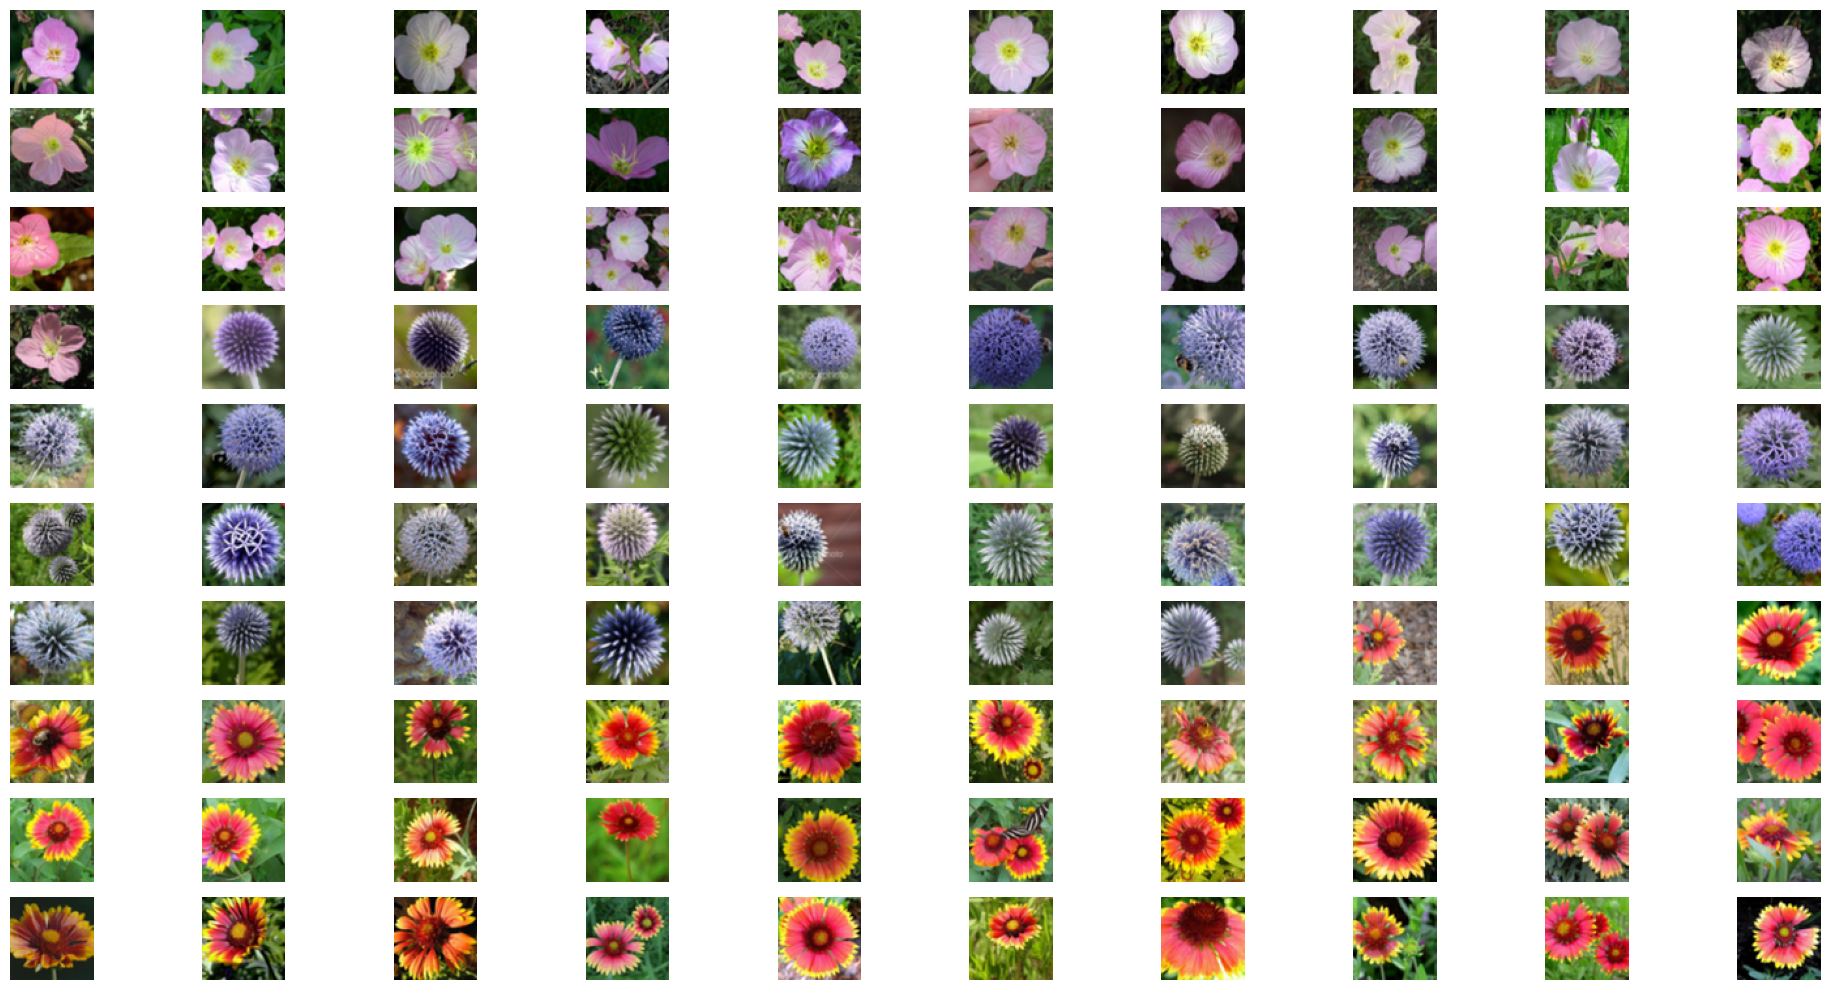

In [20]:
# Visualizar algunas flores.
fig, ejes = plt.subplots(10, 10, figsize=(20, 10))
for eje, imagen in zip(ejes.flat, imagenes[:100]):
    eje.imshow(imagen)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [21]:
np.shape(imagenes)

(100, 64, 64, 3)

Entrenamiento: (80, 64, 64, 3)
Test: (20, 64, 64, 3)


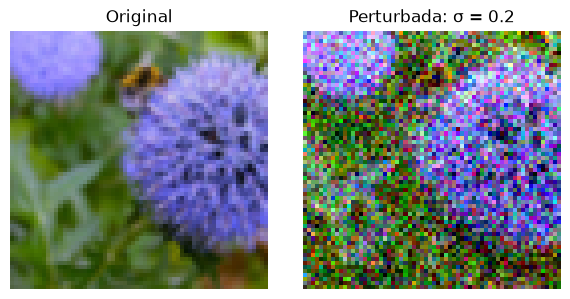

In [22]:
rng = np.random.default_rng(42)

# 1. Barajar y separar las imágenes.
indices = rng.permutation(len(imagenes))
corte = int(0.8 * len(imagenes))

entrenamiento = imagenes[indices[:corte]]
test = imagenes[indices[corte:]]

print("Entrenamiento:", entrenamiento.shape)
print("Test:", test.shape)

# 2. Perturbar todos los píxeles y canales.
sigma = 0.20  # Intensidad del ruido; las imágenes están entre 0 y 1.

def perturbar(X, sigma):
    ruido = rng.normal(size=X.shape).astype("float32")
    return X + sigma * ruido, ruido

entrenamiento_perturbado, ruido_train = perturbar(entrenamiento, sigma)
test_perturbado, ruido_test = perturbar(test, sigma)

# 3. Comparar una imagen antes y después.
i = 0

fig, ejes = plt.subplots(1, 2, figsize=(6, 3))

ejes[0].imshow(entrenamiento[i])
ejes[0].set_title("Original")

# Recortamos a [0, 1] únicamente para visualizar.
ejes[1].imshow(np.clip(entrenamiento_perturbado[i], 0, 1))
ejes[1].set_title(f"Perturbada: σ = {sigma}")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

In [23]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras import layers

keras.utils.set_random_seed(42)

modelo = keras.Sequential([
    keras.Input(shape=entrenamiento.shape[1:]),

    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),
    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),

    # Predecir el ruido de los tres canales RGB.
    layers.Conv2D(3, kernel_size=3, padding="same")
])

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo.summary()

print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

I0000 00:00:1794239405.861658    1930 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794239406.840015    1930 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,011 (43.01 KB)

 Trainable params: 11,011 (43.01 KB)

 Non-trainable params: 0 (0.00 B)

Entrada: (None, 64, 64, 3)
Salida: (None, 64, 64, 3)


In [24]:
sigma = 0.15
n_epocas = 20

perdidas_train = []
perdidas_test = []

# El test mantiene el mismo ruido durante toda la evaluación.
test_perturbado, ruido_test = perturbar(test, sigma)

for epoca in range(n_epocas):
    # Entrenamiento con ruido nuevo.
    entradas, ruido_real = perturbar(entrenamiento, sigma)

    historia = modelo.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=8,
        shuffle=True,
        verbose=0
    )

    mse_train = historia.history["loss"][0]

    # Evaluación: los pesos permanecen fijos.
    mse_test = modelo.evaluate(
        test_perturbado,
        ruido_test,
        batch_size=8,
        verbose=0
    )

    perdidas_train.append(mse_train)
    perdidas_test.append(mse_test)

    print(
        f"Época {epoca + 1:02d}/{n_epocas} | "
        f"Train: {mse_train:.4f} | Test: {mse_test:.4f}"
    )

# Graficar ambas curvas.
epocas = range(1, n_epocas + 1)


Época 01/20 | Train: 0.9635 | Test: 0.9156


Época 02/20 | Train: 0.8583 | Test: 0.7722


Época 03/20 | Train: 0.7019 | Test: 0.6114


Época 04/20 | Train: 0.5429 | Test: 0.4585


Época 05/20 | Train: 0.4010 | Test: 0.3370


Época 06/20 | Train: 0.3025 | Test: 0.2633


... (10 outputs left out)

Época 17/20 | Train: 0.1664 | Test: 0.1615


Época 18/20 | Train: 0.1644 | Test: 0.1582


Época 19/20 | Train: 0.1637 | Test: 0.1575


Época 20/20 | Train: 0.1633 | Test: 0.1574


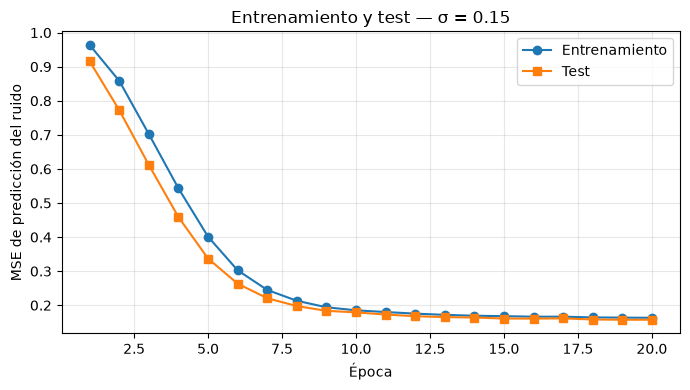

In [25]:
plt.figure(figsize=(7, 4))
plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento")
plt.plot(epocas, perdidas_test, "s-", label="Test")
plt.xlabel("Época")
plt.ylabel("MSE de predicción del ruido")
plt.title(f"Entrenamiento y test — σ = {sigma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

MSE antes:   0.022501
MSE después: 0.003542


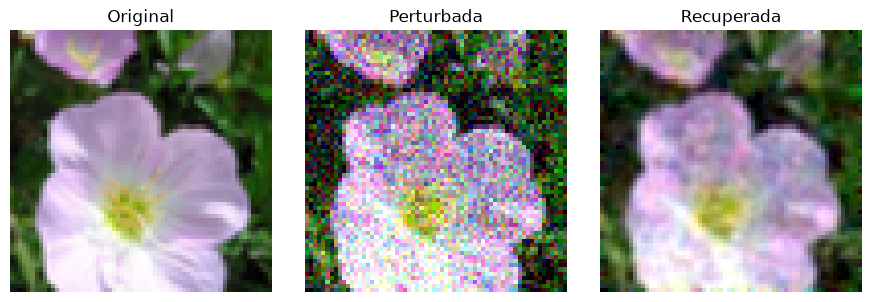

In [26]:
# Predecir el ruido y restarlo.
ruido_predicho = modelo.predict(
    test_perturbado, batch_size=8, verbose=0
)

sigma=0.15
recuperadas = test_perturbado - sigma * ruido_predicho

# Comparar el error respecto a las imágenes originales.
mse_antes = np.mean((test_perturbado - test)**2)
mse_despues = np.mean((recuperadas - test)**2)

print(f"MSE antes:   {mse_antes:.6f}")
print(f"MSE después: {mse_despues:.6f}")

# Visualizar una flor.
i = 3
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparacion = [
    (test[i], "Original"),
    (test_perturbado[i], "Perturbada"),
    (recuperadas[i], "Recuperada")
]

for eje, (imagen, titulo) in zip(ejes, comparacion):
    eje.imshow(np.clip(imagen, 0, 1))  # Recorte solo para mostrar.
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [27]:


import torch

n_imagenes = 9
n_pasos = 5000
rng_generacion = np.random.default_rng(123)

# Paso pequeño de Langevin.
h = np.float32(0.005 * sigma**2)
amplitud = np.float32(np.sqrt(2 * h))

# Inicialización independiente de las flores originales.
forma = tuple(modelo.input_shape[1:])
generadas = rng_generacion.uniform(
    0, 1, size=(n_imagenes, *forma)
).astype("float32")

# Guardar la evolución de la primera imagen.
evolucion = {0: generadas[0].copy()}
guardar_en = {50, 100, 250, n_pasos}

# Inferencia con tu backend Torch: los pesos permanecen fijos.
with torch.no_grad():
    for paso in range(1, n_pasos + 1):

        # La red predice epsilon, no sigma * epsilon.
        ruido_predicho = keras.ops.convert_to_numpy(
            modelo(generadas, training=False)
        )

        score = -ruido_predicho / sigma

        # Ruido nuevo para la dinámica de Langevin.
        z = rng_generacion.normal(
            size=generadas.shape
        ).astype("float32")

        generadas = generadas + h * score + amplitud * z

        # Mantener los valores sin recortar durante la dinámica.
        if paso in guardar_en:
            evolucion[paso] = generadas[0].copy()

        if paso % 100 == 0:
            if not np.isfinite(generadas).all():
                raise FloatingPointError(
                    "La dinámica diverge. Reduce el valor de h."
                )
            print(f"Paso {paso}/{n_pasos}")



Paso 100/5000


Paso 200/5000


Paso 300/5000


Paso 400/5000


Paso 500/5000


Paso 600/5000


... (40 outputs left out)

Paso 4700/5000


Paso 4800/5000


Paso 4900/5000


Paso 5000/5000


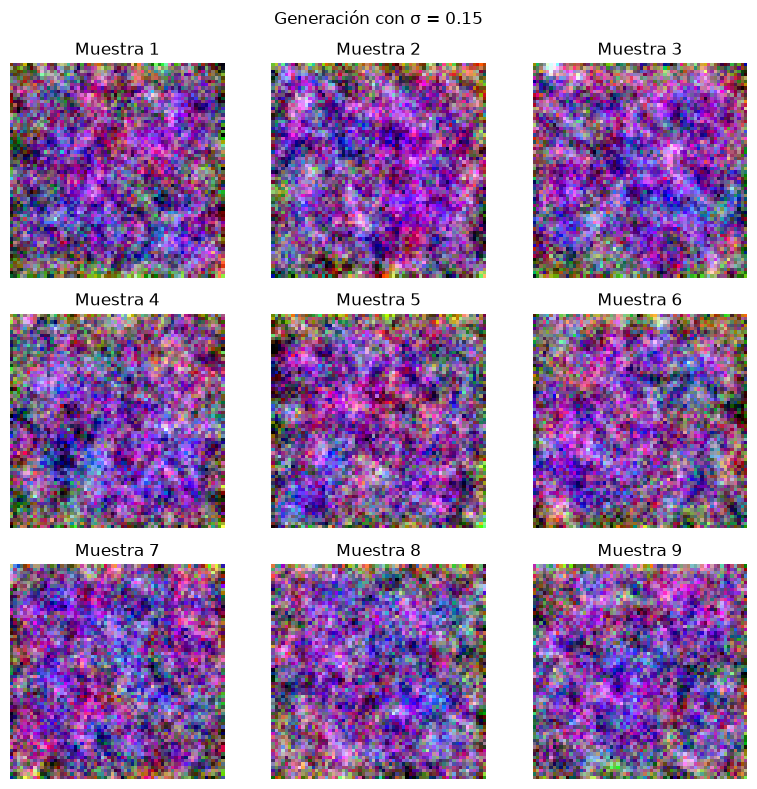

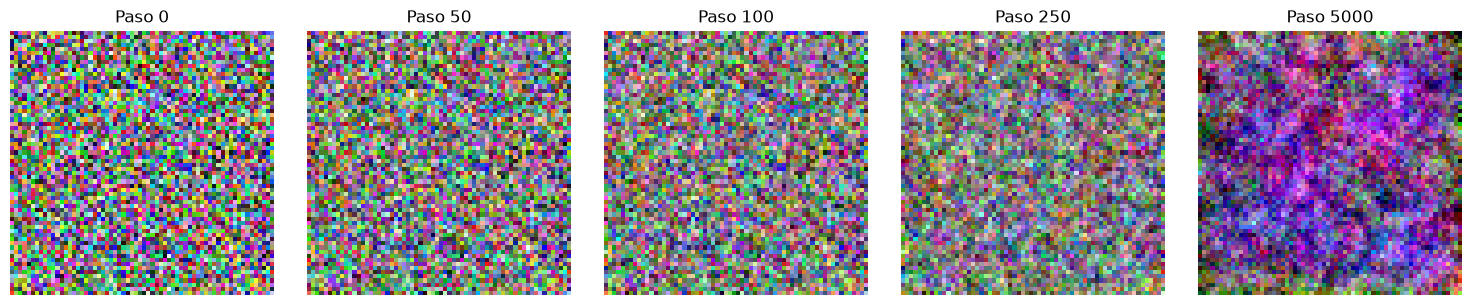

In [28]:
# Mostrar las nueve imágenes finales.
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))

for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle(f"Generación con σ = {float(sigma):.2f}")
plt.tight_layout()
plt.show()

# Mostrar cómo evolucionó la primera imagen.
fig, ejes = plt.subplots(
    1, len(evolucion), figsize=(3 * len(evolucion), 3)
)

for eje, (paso, imagen) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(f"Paso {paso}")
    eje.axis("off")

plt.tight_layout()
plt.show()


Tarea laboratorio es : Implementar una red tipo Unet, para generar imagenes con una mejor aproximación

Parámetros U-Net: 473187    CNN simple: 11011


Época 05/40 | train 0.2717 | test 0.2700 | 78 s


Época 10/40 | train 0.2293 | test 0.2274 | 200 s


Época 15/40 | train 0.2159 | test 0.2072 | 321 s


Época 20/40 | train 0.2096 | test 0.1965 | 865 s


Época 25/40 | train 0.1860 | test 0.1860 | 1229 s


Época 30/40 | train 0.1952 | test 0.1924 | 1661 s


Época 35/40 | train 0.1787 | test 0.1767 | 2154 s


Época 40/40 | train 0.1728 | test 0.1750 | 2721 s


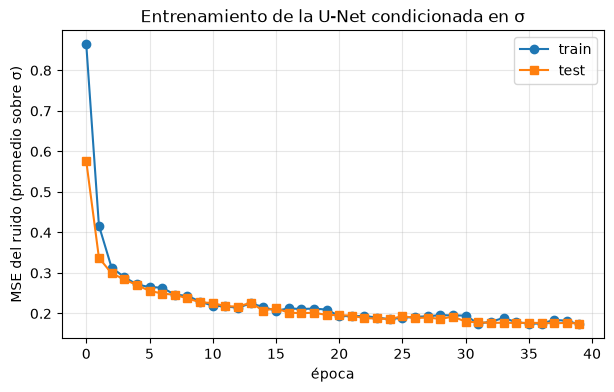

In [29]:
# ============================================================
# Tarea: U-Net condicionada en el nivel de ruido (modelo tipo NCSN)
# ============================================================
# Mejoras respecto a la CNN de 3 capas:
#  1. Arquitectura U-Net: codificador (baja resolución, campo receptivo grande) + decodificador,
#     con conexiones de salto que conservan los detalles finos.
#  2. La red recibe σ como entrada (un canal extra constante = log σ), así UN SOLO modelo aprende el score
#     para muchos niveles de ruido, de σ_max (estructura global) a σ_min (detalles).
#  3. La generación usa Langevin anillado: se empieza con σ grande y se baja gradualmente.
import time
from keras import ops

sigmas_u = np.geomspace(0.8, 0.02, 10).astype("float32")     # niveles de ruido (imágenes en [0, 1])

def bloque_conv(x, filtros):
    for _ in range(2):
        x = layers.Conv2D(filtros, 3, padding="same")(x)
        x = layers.GroupNormalization(groups=8)(x)
        x = layers.Activation("swish")(x)
    return x

def construir_unet(forma=(64, 64, 3), base=32):
    imagen = keras.Input(forma, name="imagen_ruidosa")
    mapa_sigma = keras.Input(forma[:2] + (1,), name="log_sigma")
    x0 = layers.Concatenate()([imagen, mapa_sigma])

    c1 = bloque_conv(x0, base)                                  # 64x64
    c2 = bloque_conv(layers.AveragePooling2D(2)(c1), 2 * base)  # 32x32
    c3 = bloque_conv(layers.AveragePooling2D(2)(c2), 4 * base)  # 16x16 (cuello de botella)

    u2 = layers.UpSampling2D(2, interpolation="bilinear")(c3)
    u2 = bloque_conv(layers.Concatenate()([u2, c2]), 2 * base)  # conexión de salto
    u1 = layers.UpSampling2D(2, interpolation="bilinear")(u2)
    u1 = bloque_conv(layers.Concatenate()([u1, c1]), base)      # conexión de salto

    salida = layers.Conv2D(3, 1, name="ruido_predicho")(u1)    # predice ε (ruido unitario)
    return keras.Model([imagen, mapa_sigma], salida, name="unet_ncsn")

keras.utils.set_random_seed(0)
unet = construir_unet(entrenamiento.shape[1:])
unet.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
print("Parámetros U-Net:", unet.count_params(), "   CNN simple:", modelo.count_params())

def mapa(s, n):
    """Canal de condicionamiento: log σ repetido en todos los píxeles. s puede ser escalar o vector de largo n."""
    s = np.broadcast_to(np.asarray(s, dtype="float32"), (n,))
    return np.log(s)[:, None, None, None] * np.ones((1, 64, 64, 1), dtype="float32")

rng_u = np.random.default_rng(1)
def lote_entrenamiento(X, replicas=4):
    """Aumenta datos con reflejo horizontal, elige un σ al azar por imagen y añade ruido nuevo."""
    Xa = np.concatenate([X, X[:, :, ::-1]])
    Xa = np.repeat(Xa, replicas, axis=0)
    s = rng_u.choice(sigmas_u, size=len(Xa)).astype("float32")
    eps = rng_u.normal(size=Xa.shape).astype("float32")
    return [Xa + s[:, None, None, None] * eps, mapa(s, len(Xa))], eps

# Conjunto de test fijo: cada imagen de test con cada nivel de σ
s_test = np.repeat(sigmas_u, len(test)).astype("float32")
X_test_rep = np.tile(test, (len(sigmas_u), 1, 1, 1))
eps_test = np.random.default_rng(99).normal(size=X_test_rep.shape).astype("float32")
entrada_test = [X_test_rep + s_test[:, None, None, None] * eps_test, mapa(s_test, len(s_test))]

n_epocas_u = 40
hist_u_train, hist_u_test = [], []
t0 = time.time()
for ep in range(n_epocas_u):
    if ep == 30:
        unet.optimizer.learning_rate.assign(3e-4)
    entradas_u, objetivo_u = lote_entrenamiento(entrenamiento)
    h_ = unet.fit(entradas_u, objetivo_u, batch_size=16, epochs=1, shuffle=True, verbose=0)
    hist_u_train.append(h_.history["loss"][0])
    hist_u_test.append(unet.evaluate(entrada_test, eps_test, batch_size=32, verbose=0))
    if (ep + 1) % 5 == 0:
        print(f"Época {ep+1:02d}/{n_epocas_u} | train {hist_u_train[-1]:.4f} | test {hist_u_test[-1]:.4f} | {time.time()-t0:.0f} s")

plt.figure(figsize=(7, 4))
plt.plot(hist_u_train, "o-", label="train"); plt.plot(hist_u_test, "s-", label="test")
plt.xlabel("época"); plt.ylabel("MSE del ruido (promedio sobre σ)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Entrenamiento de la U-Net condicionada en σ"); plt.show()


   σ  MSE con ruido  MSE CNN simple  MSE U-Net  PSNR U-Net (dB)
0.05        0.00250         0.00145    0.00063        31.972771
0.10        0.00996         0.00281    0.00154        28.123569
0.15        0.02251         0.00356    0.00254        25.957880
0.30        0.09034         0.05863    0.00570        22.444990
0.50        0.24917         0.62317    0.01061        19.742640

(La CNN simple solo se entrenó con σ = 0.15; en los otros niveles se usa fuera de su rango.)


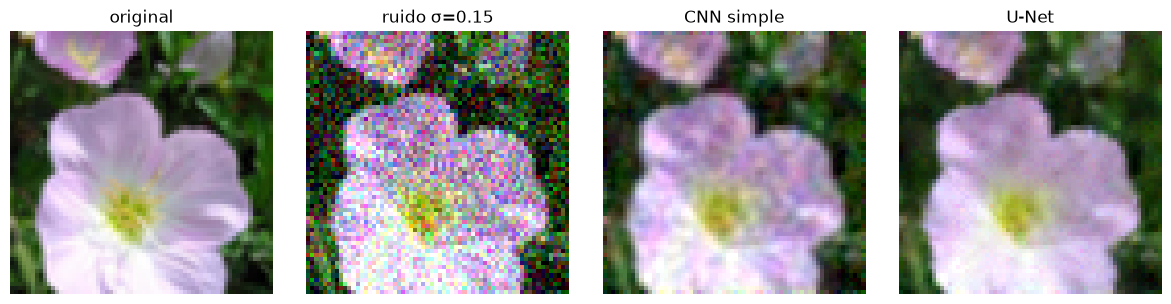

In [30]:
# Comparación de la calidad del denoising: CNN simple (entrenada solo con σ = 0.15) vs U-Net
def denoise_unet(Yr, s):
    eps_hat = keras.ops.convert_to_numpy(unet([Yr, mapa(np.full(len(Yr), s, "float32"), len(Yr))], training=False))
    return Yr - s * eps_hat

rng_c = np.random.default_rng(7)
filas_c = []
for s in [0.05, 0.10, 0.15, 0.30, 0.50]:
    Yr = (test + s * rng_c.normal(size=test.shape)).astype("float32")
    mse_ruido = np.mean((Yr - test)**2)
    mse_u = np.mean((denoise_unet(Yr, s) - test)**2)
    mse_cnn = np.mean((Yr - s * keras.ops.convert_to_numpy(modelo(Yr, training=False)) - test)**2)
    filas_c.append((s, mse_ruido, mse_cnn, mse_u))
import pandas as pd
tabla = pd.DataFrame(filas_c, columns=["σ", "MSE con ruido", "MSE CNN simple", "MSE U-Net"])
tabla["PSNR U-Net (dB)"] = 10 * np.log10(1 / tabla["MSE U-Net"])
print(tabla.round(5).to_string(index=False))
print("\n(La CNN simple solo se entrenó con σ = 0.15; en los otros niveles se usa fuera de su rango.)")

i = 3; s = 0.15
Yr = (test[i:i+1] + s * np.random.default_rng(3).normal(size=test[i:i+1].shape)).astype("float32")
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a_, im_, t_ in zip(ax, [test[i], Yr[0], Yr[0] - s * keras.ops.convert_to_numpy(modelo(Yr))[0], denoise_unet(Yr, s)[0]],
                       ["original", f"ruido σ={s}", "CNN simple", "U-Net"]):
    a_.imshow(np.clip(im_, 0, 1)); a_.set_title(t_); a_.axis("off")
plt.tight_layout(); plt.show()


Generación: 336 s


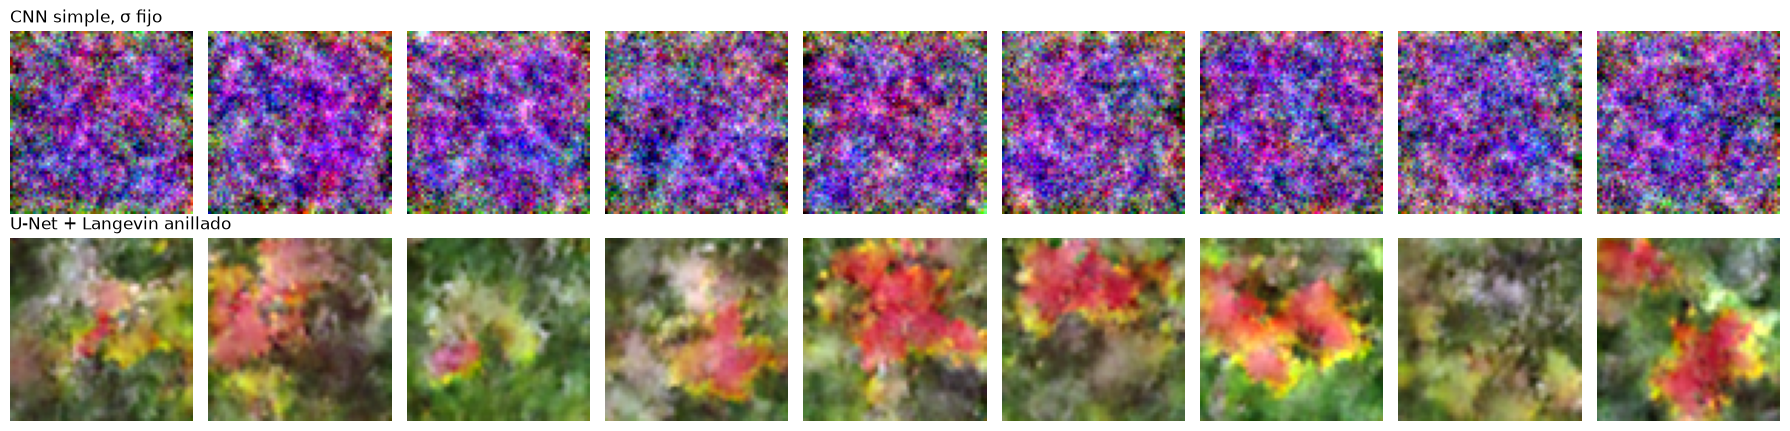

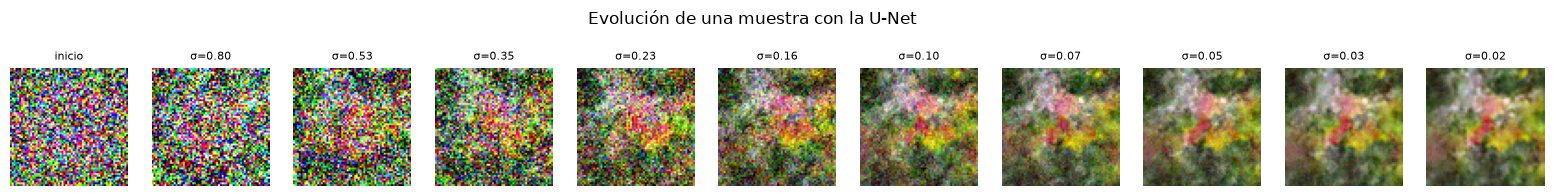

MSE a la flor de entrenamiento más cercana:  U-Net 0.0474   CNN simple 0.0825   (referencia: flores de test reales 0.0560)


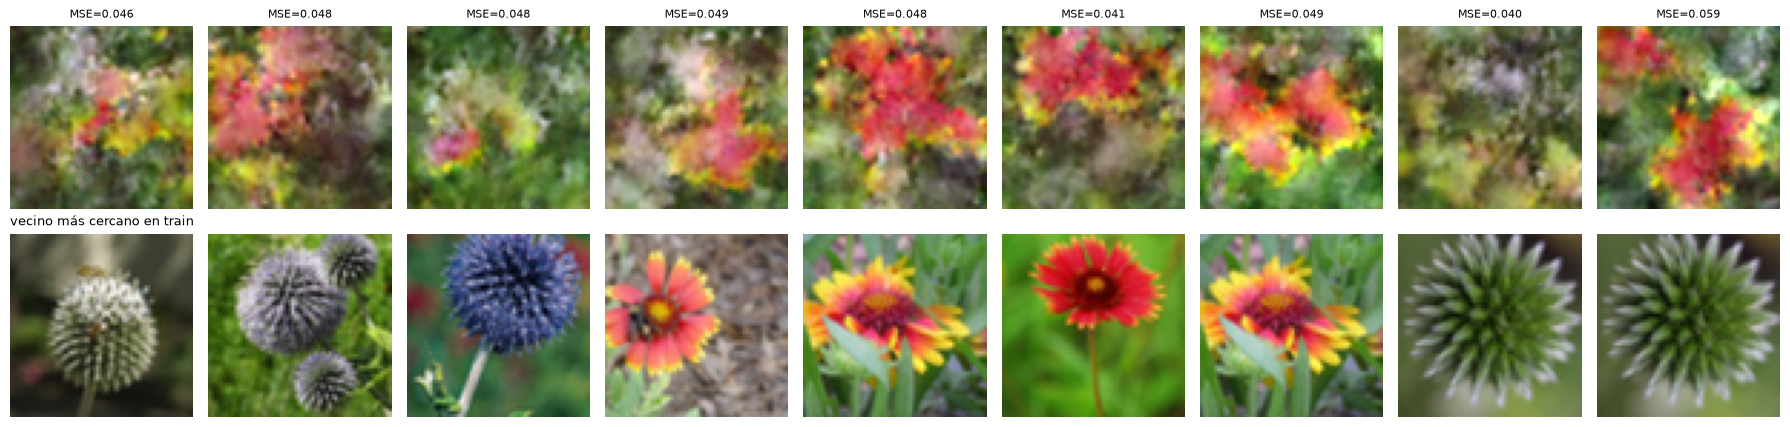

In [31]:
# Generación con Langevin anillado usando la U-Net
def generar_unet(n, K=60, c=0.08, seed=0):
    rng_ = np.random.default_rng(seed)
    media = entrenamiento.mean(axis=0)
    Y = (media + sigmas_u[0] * rng_.normal(size=(n,) + media.shape)).astype("float32")
    hist = [Y[0].copy()]
    with torch.no_grad():
        for s in sigmas_u:
            h = np.float32(c * s**2)
            m_s = mapa(np.full(n, s, "float32"), n)
            for _ in range(K):
                eps_hat = keras.ops.convert_to_numpy(unet([Y, m_s], training=False))
                Y = Y + h * (-eps_hat / s) + np.sqrt(2 * h) * rng_.normal(size=Y.shape).astype("float32")
            hist.append(Y[0].copy())
        # recuperación final (Tweedie) con σ_min
        Y = denoise_unet(Y, sigmas_u[-1])
    return Y, hist

t0 = time.time()
gen_u, hist_gen = generar_unet(9)
print(f"Generación: {time.time()-t0:.0f} s")

fig, ax = plt.subplots(2, 9, figsize=(18, 4.4))
for k in range(9):
    ax[0, k].imshow(np.clip(generadas[k], 0, 1)); ax[0, k].axis("off")
    ax[1, k].imshow(np.clip(gen_u[k], 0, 1)); ax[1, k].axis("off")
ax[0, 0].set_title("CNN simple, σ fijo", loc="left"); ax[1, 0].set_title("U-Net + Langevin anillado", loc="left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, len(hist_gen), figsize=(1.8 * len(hist_gen), 2))
for k, (a_, im_) in enumerate(zip(ax, hist_gen)):
    a_.imshow(np.clip(im_, 0, 1)); a_.axis("off")
    a_.set_title("inicio" if k == 0 else f"σ={sigmas_u[k-1]:.2f}", fontsize=8)
plt.suptitle("Evolución de una muestra con la U-Net", y=1.08); plt.show()

# ¿Las muestras son nuevas o copias de flores de entrenamiento? Distancia a la flor más parecida.
def dist_min(G, ref):
    d = ((G[:, None] - ref[None])**2).mean(axis=(2, 3, 4))
    return d.min(axis=1), d.argmin(axis=1)
d_u, idx_u = dist_min(gen_u, entrenamiento)
d_c, _ = dist_min(generadas, entrenamiento)
d_tt, _ = dist_min(test, entrenamiento)
print(f"MSE a la flor de entrenamiento más cercana:  U-Net {d_u.mean():.4f}   CNN simple {d_c.mean():.4f}"
      f"   (referencia: flores de test reales {d_tt.mean():.4f})")

fig, ax = plt.subplots(2, 9, figsize=(18, 4.4))
for k in range(9):
    ax[0, k].imshow(np.clip(gen_u[k], 0, 1)); ax[0, k].axis("off"); ax[0, k].set_title(f"MSE={d_u[k]:.3f}", fontsize=8)
    ax[1, k].imshow(entrenamiento[idx_u[k]]); ax[1, k].axis("off")
ax[0, 0].set_ylabel("generada"); ax[1, 0].set_title("vecino más cercano en train", loc="left", fontsize=9)
plt.tight_layout(); plt.show()


## Conclusiones de la tarea (U-Net)

**Qué se cambió respecto a la CNN de tres capas**

1. **Arquitectura U-Net.** Un codificador baja la resolución de 64×64 a 16×16, con lo que el campo receptivo cubre toda la flor. Un decodificador la recupera, y las **conexiones de salto** conservan los detalles finos. Se usa *GroupNorm* y activación *swish*; son 473 mil parámetros frente a 11 mil de la CNN.
2. **Condicionamiento en σ.** La red recibe $\log\sigma$ como un canal extra y se entrena con 10 niveles de ruido, de $\sigma = 0.8$ a $0.02$. Así un solo modelo aprende el score de toda la familia de distribuciones perturbadas (modelo tipo NCSN).
3. **Langevin anillado.** La generación empieza con ruido grande, que fija la estructura global (colores, composición), y baja σ gradualmente para afinar los detalles. Al final se aplica un paso de Tweedie, $\hat x = y + \sigma^2 s_\theta(y)$.
4. **Aumento de datos.** Se usan reflejos horizontales y ruido nuevo en cada época, porque solo hay 80 flores de entrenamiento.

**Resultados**

- **Denoising en test.** En σ = 0.15, el único nivel donde se entrenó la CNN, la U-Net obtiene un MSE de 0.0025 frente a 0.0036 de la CNN, unos 30 % menos. En los otros niveles la ventaja es mucho mayor: con σ = 0.5 la CNN empeora la imagen (MSE 0.62 frente a 0.25 sin denoising), mientras la U-Net la deja en 0.011.
- **Generación.** La CNN de σ fijo produce ruido coloreado: su score solo es válido muy cerca de los datos, y con ruido de inicio uniforme nunca llega a ellos. La U-Net con Langevin anillado genera imágenes con **estructura de flor**: manchas rojas y amarillas (como las gaillardias del conjunto) sobre fondos verdes, con la estadística de color y textura de las fotos.
- **¿Memoriza?** No copia las flores de entrenamiento. El MSE a la flor más parecida del entrenamiento es 0.047, del mismo orden que el de las flores reales de test (0.056). Las muestras son combinaciones nuevas, aunque todavía borrosas: con solo 80 imágenes, un entrenamiento de 40 épocas en CPU y una red pequeña, el modelo captura colores y texturas pero no la forma nítida de los pétalos.

**Cómo mejorarlo:** más imágenes (por ejemplo, todo Oxford Flowers), más épocas y una GPU, una U-Net más profunda con atención, embebido sinusoidal de σ en lugar de un canal constante, y más pasos de Langevin por nivel, o pasar a un modelo de difusión tipo DDPM.

> **Tiempo de ejecución:** en CPU, el entrenamiento de la U-Net tardó unos 45 minutos y la generación unos 6 minutos. Con GPU (por ejemplo, en Colab) es mucho más rápido.
